In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("annual-temperature-anomalies.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print("Column Names:")
print(df.columns.tolist())

df.head()


Dataset Loaded Successfully!
Dataset Shape: (18318, 4)
Column Names:
['Entity', 'Code', 'Year', 'Temperature anomaly']


,Entity,Code,Year,Temperature anomaly
0,Afghanistan,AFG,1940,-1.202316
1,Afghanistan,AFG,1941,0.794745
2,Afghanistan,AFG,1942,0.355437
3,Afghanistan,AFG,1943,-1.005242
4,Afghanistan,AFG,1944,-0.386346


In [2]:

print(df.columns.tolist())
print(df.head())


['Entity', 'Code', 'Year', 'Temperature anomaly']
        Entity Code  Year  Temperature anomaly
0  Afghanistan  AFG  1940            -1.202316
1  Afghanistan  AFG  1941             0.794745
2  Afghanistan  AFG  1942             0.355437
3  Afghanistan  AFG  1943            -1.005242
4  Afghanistan  AFG  1944            -0.386346


In [3]:

# Select global records
print(df["Entity"].unique())


<ArrowStringArray>
[                 'Afghanistan',               'Africa (NIAID)',
                      'Albania',                      'Algeria',
               'American Samoa',                      'Andorra',
                       'Angola',                     'Anguilla',
           'Antarctica (NIAID)',          'Antigua and Barbuda',
 ...
 'United States Virgin Islands',                      'Uruguay',
                   'Uzbekistan',                      'Vanuatu',
                    'Venezuela',                      'Vietnam',
                        'World',                        'Yemen',
                       'Zambia',                     'Zimbabwe']
Length: 213, dtype: str


In [4]:

print(df.columns.tolist())


['Entity', 'Code', 'Year', 'Temperature anomaly']


In [5]:

# Display column names clearly
for col in df.columns:
    print(col, ":", df[col].dtype)

print("\nSample records:")
display(df.head(10))


Entity : str
Code : str
Year : int64
Temperature anomaly : float64

Sample records:


,Entity,Code,Year,Temperature anomaly
0,Afghanistan,AFG,1940,-1.202316
1,Afghanistan,AFG,1941,0.794745
2,Afghanistan,AFG,1942,0.355437
3,Afghanistan,AFG,1943,-1.005242
4,Afghanistan,AFG,1944,-0.386346
5,Afghanistan,AFG,1945,-1.163426
6,Afghanistan,AFG,1946,-0.091273
7,Afghanistan,AFG,1947,-0.186726
8,Afghanistan,AFG,1948,-0.725991
9,Afghanistan,AFG,1949,-2.020418


In [6]:

# Display dataset columns
print(df.columns.tolist())


['Entity', 'Code', 'Year', 'Temperature anomaly']


In [7]:

# Check available columns and sample data
display(df.head())
print("Columns:", df.columns.tolist())


,Entity,Code,Year,Temperature anomaly
0,Afghanistan,AFG,1940,-1.202316
1,Afghanistan,AFG,1941,0.794745
2,Afghanistan,AFG,1942,0.355437
3,Afghanistan,AFG,1943,-1.005242
4,Afghanistan,AFG,1944,-0.386346


Columns: ['Entity', 'Code', 'Year', 'Temperature anomaly']


In [8]:

# Check the dataset columns
print(df.columns.tolist())


['Entity', 'Code', 'Year', 'Temperature anomaly']


In [9]:

# Select global records
global_df = df[
    df["Entity"].astype(str).str.contains(
        "World|Global", case=False, regex=True
    )
].copy()

print(global_df.head())
print("Number of global records:", len(global_df))


      Entity      Code  Year  Temperature anomaly
17974  World  OWID_WRL  1940            -0.686135
17975  World  OWID_WRL  1941            -0.641774
17976  World  OWID_WRL  1942            -0.732430
17977  World  OWID_WRL  1943            -0.726379
17978  World  OWID_WRL  1944            -0.534997
Number of global records: 86


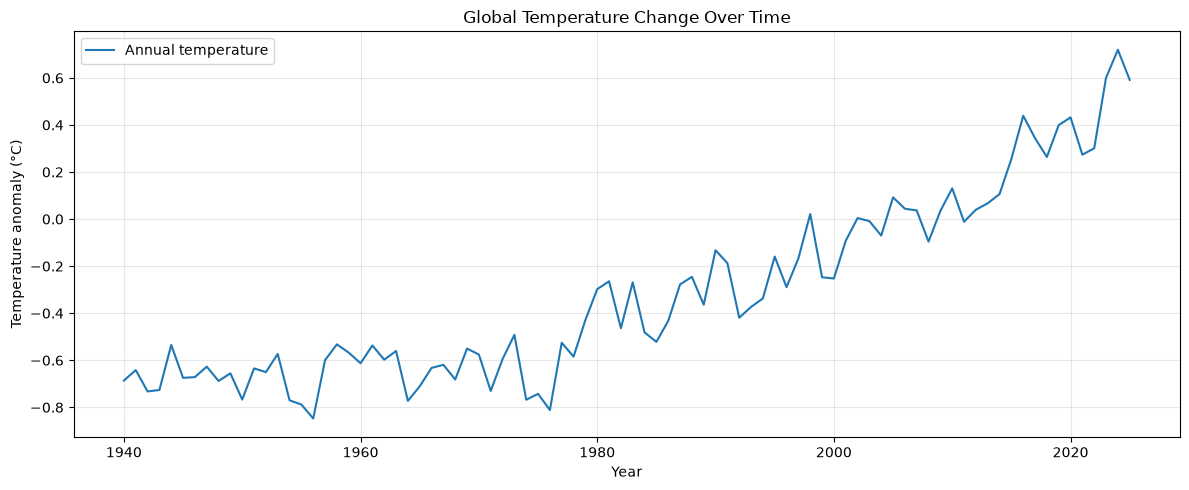

Line graph created successfully!


In [10]:

# Global Temperature Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Create output folder
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Identify the year and temperature columns
year_col = next(
    (c for c in global_df.columns
     if c.lower() == "year"),
    None
)

temp_col = next(
    (c for c in global_df.columns
     if "temp" in c.lower() or "anomal" in c.lower()),
    None
)

if year_col is None or temp_col is None:
    print("Available columns:", global_df.columns.tolist())
else:
    # Clean and sort data
    analysis = global_df[[year_col, temp_col]].copy()
    analysis.columns = ["Year", "Temperature"]
    analysis["Year"] = pd.to_numeric(
        analysis["Year"], errors="coerce"
    )
    analysis["Temperature"] = pd.to_numeric(
        analysis["Temperature"], errors="coerce"
    )
    analysis = analysis.dropna().sort_values("Year")

    # Line graph
    plt.figure(figsize=(12, 5))
    plt.plot(
        analysis["Year"],
        analysis["Temperature"],
        label="Annual temperature"
    )
    plt.title("Global Temperature Change Over Time")
    plt.xlabel("Year")
    plt.ylabel("Temperature anomaly (°C)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_dir / "temperature_trend.png", dpi=300)
    plt.show()

    print("Line graph created successfully!")


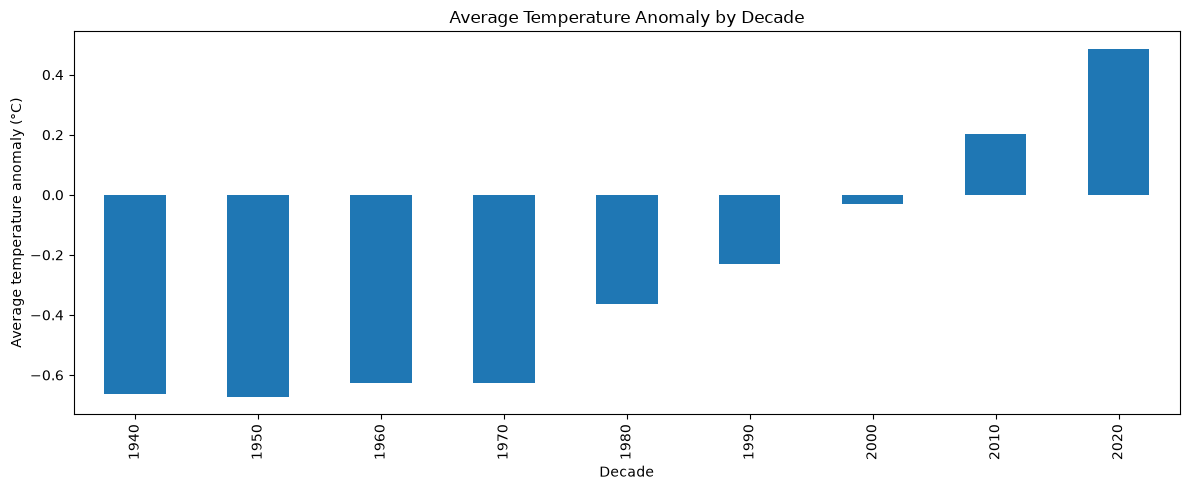

Decade comparison graph created!


In [11]:

# Calculate average temperature by decade

analysis["Decade"] = (analysis["Year"] // 10) * 10

decade_data = analysis.groupby("Decade")["Temperature"].mean()

plt.figure(figsize=(12, 5))
decade_data.plot(kind="bar")
plt.title("Average Temperature Anomaly by Decade")
plt.xlabel("Decade")
plt.ylabel("Average temperature anomaly (°C)")
plt.tight_layout()
plt.savefig(output_dir / "decade_comparison.png", dpi=300)
plt.show()

print("Decade comparison graph created!")


In [12]:

print("GLOBAL TEMPERATURE ANALYSIS")
print("----------------------------")
print("Total records:", len(analysis))
print("First year:", int(analysis["Year"].min()))
print("Last year:", int(analysis["Year"].max()))
print("Mean temperature value:",
      round(analysis["Temperature"].mean(), 3))
print("Maximum temperature value:",
      round(analysis["Temperature"].max(), 3))
print("Minimum temperature value:",
      round(analysis["Temperature"].min(), 3))

analysis.to_csv(
    output_dir / "analysed_temperature.csv",
    index=False
)

print("\nAll analysis results saved successfully!")


GLOBAL TEMPERATURE ANALYSIS
----------------------------
Total records: 86
First year: 1940
Last year: 2025
Mean temperature value: -0.316
Maximum temperature value: 0.72
Minimum temperature value: -0.847

All analysis results saved successfully!


Dataset Loaded Successfully!
Dataset Shape: (18318, 4)
        Entity Code  Year  Temperature anomaly
0  Afghanistan  AFG  1940            -1.202316
1  Afghanistan  AFG  1941             0.794745
2  Afghanistan  AFG  1942             0.355437
3  Afghanistan  AFG  1943            -1.005242
4  Afghanistan  AFG  1944            -0.386346

Column Names:
['Entity', 'Code', 'Year', 'Temperature anomaly']

Global Records:
      Entity      Code  Year  Temperature anomaly
17974  World  OWID_WRL  1940            -0.686135
17975  World  OWID_WRL  1941            -0.641774
17976  World  OWID_WRL  1942            -0.732430
17977  World  OWID_WRL  1943            -0.726379
17978  World  OWID_WRL  1944            -0.534997

GLOBAL TEMPERATURE ANALYSIS
Total Records: 86
First Year: 1940
Last Year: 2025
Mean: -0.316
Maximum: 0.72
Minimum: -0.847


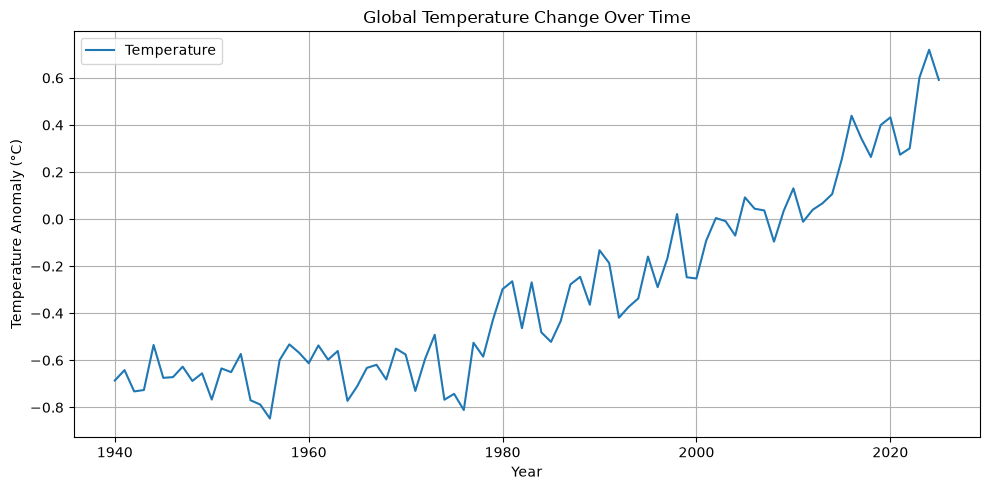

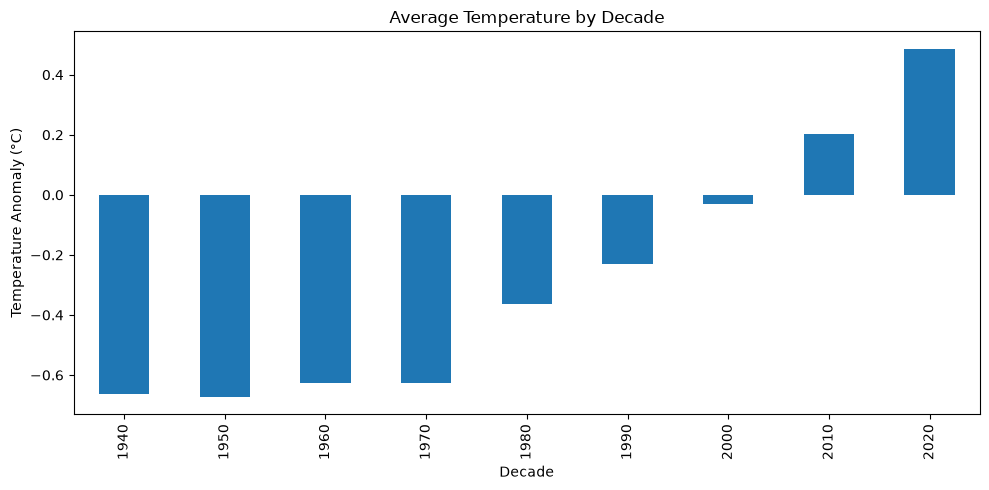


Project Completed Successfully!
Graphs and analysed data saved in outputs folder.


In [13]:

# Global Temperature Change and Climate Patterns
# Data Science Project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Load Dataset
df = pd.read_csv("annual-temperature-anomalies.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print(df.head())

# 2. Display Dataset Columns
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Select Global Temperature Data
global_df = df[
    df["Entity"].astype(str).str.contains(
        "World|Global", case=False, regex=True
    )
].copy()

print("\nGlobal Records:")
print(global_df.head())

# 4. Identify Columns
year_col = "Year"
temp_col = next(
    col for col in global_df.columns
    if "temp" in col.lower() or "anomal" in col.lower()
)

# 5. Clean Data
analysis = global_df[[year_col, temp_col]].copy()
analysis.columns = ["Year", "Temperature"]

analysis["Year"] = pd.to_numeric(
    analysis["Year"], errors="coerce"
)
analysis["Temperature"] = pd.to_numeric(
    analysis["Temperature"], errors="coerce"
)

analysis = analysis.dropna().sort_values("Year")

# 6. Statistical Analysis
print("\nGLOBAL TEMPERATURE ANALYSIS")
print("Total Records:", len(analysis))
print("First Year:", int(analysis["Year"].min()))
print("Last Year:", int(analysis["Year"].max()))
print("Mean:", round(analysis["Temperature"].mean(), 3))
print("Maximum:", round(analysis["Temperature"].max(), 3))
print("Minimum:", round(analysis["Temperature"].min(), 3))

# 7. Create Output Folder
os.makedirs("outputs", exist_ok=True)

# 8. Line Graph
plt.figure(figsize=(10, 5))
plt.plot(
    analysis["Year"],
    analysis["Temperature"],
    label="Temperature"
)
plt.title("Global Temperature Change Over Time")
plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("outputs/temperature_trend.png", dpi=300)
plt.show()

# 9. Decade-wise Analysis
analysis["Decade"] = (analysis["Year"] // 10) * 10
decade_avg = analysis.groupby("Decade")["Temperature"].mean()

plt.figure(figsize=(10, 5))
decade_avg.plot(kind="bar")
plt.title("Average Temperature by Decade")
plt.xlabel("Decade")
plt.ylabel("Temperature Anomaly (°C)")
plt.tight_layout()
plt.savefig("outputs/decade_comparison.png", dpi=300)
plt.show()

# 10. Save Results
analysis.to_csv("outputs/analysed_temperature.csv", index=False)

print("\nProject Completed Successfully!")
print("Graphs and analysed data saved in outputs folder.")
